In [21]:
# Below is a Python implementation of a Genetic Algorithm (GA) 
# to solve the Traveling Salesman Problem (TSP). This code includes 
# essential components such as creating an initial population, 
# selection, crossover, mutation, and calculating the fitness of routes.
#

In [22]:
import numpy as np
import random
import time
import copy
import matplotlib.pyplot as plt

In [23]:
# PART 1: TSP by Genetic Algorithm (no elite)
count_calculate_fitness=0

class GeneticAlgorithm:
    
    # The `GeneticAlgorithm` class initializes the distance matrix, population size, mutation rate, 
    # and number of generations. It also creates an initial population of random routes.
    # population_size=200, mutation_rate=0.01, generations=100
    
    def __init__(self, distance_matrix, population_size=200, mutation_rate=0.01, generations=100):
        self.distance_matrix = distance_matrix
        self.population_size = population_size
        self.mutation_rate = mutation_rate
        self.generations = generations
        self.num_cities = len(distance_matrix)
        self.population = self.create_initial_population()
        
    def create_initial_population(self):
        print('inside initial ')
        """1. Create an initial population of random routes."""
        population = []
        for _ in range(self.population_size):
            route = list(range(self.num_cities))
            random.shuffle(route)  #randomize the list of cities and add to the population
            population.append(route)
        return population

    def calculate_fitness(self, route):
        """2. Calculate the fitness (inverse of distance) of a route."""
        total_distance = 0
        
        global count_calculate_fitness
        count_calculate_fitness = count_calculate_fitness + 1
        
        for i in range(len(route) - 1):
            total_distance += self.distance_matrix[route[i]][route[i + 1]]
        total_distance += self.distance_matrix[route[-1]][route[0]]  # Return to starting point
        #print('total_distance ',total_distance)
        return 1 / total_distance  # Fitness is the inverse of distance; the larger the better

    def select_parents(self):
        #print('inside select_parents')
        """Select two parents based on their fitness using tournament selection."""
        """where a subset of the population is chosen randomly, and the best 
           among them is selected."""

        tournament_size = 5
        tournament = random.sample(self.population, tournament_size)
        #print('before sort - ', tournament)
        tournament.sort(key=self.calculate_fitness, reverse=True)
        #print('after sort - ', tournament)
        return tournament[0], tournament[1]  # The best two candidates are returned

    def crossover(self, parent1, parent2):
        #print('inside crossover')
        
        """Perform crossover between two parents to create a child."""
        """A crossover operation creates a child route by combining 
        segments of two parent routes."""

        start, end = sorted(random.sample(range(self.num_cities), 2))
        child = [-1] * self.num_cities
        
        #print("----------------------------")
        #print('parent1=',parent1,'  parent2=',parent2)
        #print('start=',start, '  end=', end, '  child=',child)
        #print('Setup: child[start:end] = parent1[start:end] ')
        child[start:end] = parent1[start:end]
        #print('Result:  child=',child)
        current_position = end
        for city in parent2:
            if city not in child:
                child[current_position] = city
                current_position = (current_position + 1) % self.num_cities           
        #print('Final Result:  child=',child)
        return child

    def mutate(self, route):
        """Mutate a route by swapping two cities in a route based on the mutation rate."""
        #print('inside mutate')
        for i in range(self.num_cities):
            if random.random() < self.mutation_rate:
                j = random.randint(0, self.num_cities - 1)
                route[i], route[j] = route[j], route[i]

    def evolve(self):
        """Evolve the population over generations."""
        counter = 0
        save_shortest_dist =[]
        
        # In each generation, there are 200 + 1 + (200 x 5) number of fitness count
        # Details:
        # best_route_tmp has 200
        # best_distance_tmp has 1
        # self.select_parents() has 5 per candidate in population; hence 200 x 5.
        # Total: if number_generation=100; population=200, it would be 1201 x 100
        
        for kk in range(self.generations):  # for _ in range(self.generations):
            new_population = []
            counter = counter + 1
            # To get the best among the population in the current generation
            best_route_tmp = max(self.population, key=self.calculate_fitness)           
            best_distance_tmp = 1 / self.calculate_fitness(best_route_tmp)
            save_shortest_dist.append([counter, best_distance_tmp ])
            
            for _ in range(self.population_size):
                parent1, parent2 = self.select_parents()  #select two best parents/candidates
                child = self.crossover(parent1, parent2)  # crossover to get a child
                self.mutate(child)                        # mutate the child
                new_population.append(child)
            self.population = new_population          
        return save_shortest_dist

    def get_best_route(self):
        """Get the best route from the current population."""
        best_route = max(self.population, key=self.calculate_fitness)
        best_distance = 1 / self.calculate_fitness(best_route)
        print('total number of routes by GA = ',count_calculate_fitness)
        return best_route, best_distance, count_calculate_fitness


In [25]:
# Example distance matrix (symmetric)
# distance_matrix = [
#    [0, 10, 15, 20],
#    [10, 0, 35, 25],
#    [15, 35, 0, 30],
#    [20, 25, 30, 0]
# ]

In [26]:
# Asian City flight distance matrix (symmetric)
# # population_size=200, mutation_rate=0.01, generations=100
# for 7 x 7 matrix; Time taken: 0.38 seconds 120301 fitness count; 
#       brute force Time taken: 0.03 seconds (7! = 5040 routes)

# population_size=200, mutation_rate=0.01, generations=100
# for 8 x 8 matrix; Time taken: 0.47 seconds; 120301 fitness count;
#       brute force Time taken: 0.11 seconds (8! = 40320 routes)

# population_size=200, mutation_rate=0.01, generations=100
# for 9 x 9 matrix; Time taken: 0.48 seconds; 120301 fitness count;
#       brute force Time taken: 0.48 seconds (9! = 362880 routes)

# population_size=200, mutation_rate=0.01, generations=100
# for 10 x 10 matrix; Time taken: 0.49 seconds 120301 fitness count; 
#         brute force Time taken: 4.68  seconds (10! = 3628800 routes)

# Distance matrix (symmetric): ten Asian cities
distance_matrix = [
    [0, 2526,800,2555,1144,847,1987,2065,898,1492],
    [2526,0,1814,4982,4800,2785,1890,837,2700,3988],
    [800,1814,0,3213, 1170, 1635, 1720,1450,1430,2206],
    [2555,4982,3213,0,2370,2198, 4490,4600,1966,1087],
    [1144, 4800, 1170, 2370, 0, 1773, 2807,2610,1307,1610],
    [847,2785,1635,2198,1773,0,2332,2700,497,1160],
    [1987,1890,1720,4490,2807,2332,0,904,2510,2105],
    [2065,837,1450,4600,2610,2700,904,0,2724,3550],
    [898,2700,1430,1966,1307,497,2510,2724,0,885],
    [1492,3988,2206,1087,1610,1160,2105,3550,885,0]
]

In [27]:
# Running the Genetic Algorithm for TSP
# Calcuate the time taken
ga = GeneticAlgorithm(distance_matrix)

start_time = time.time()
tsp_result = ga.evolve()

best_route, min_distance, fitness_count = ga.get_best_route()
print('count_calculate_fitness final (with)= ', count_calculate_fitness)

end_time = time.time()
# Calculate the time taken
time_taken = end_time - start_time 
print(f"Time taken: {time_taken:.2f} seconds")

print("Best Route:", best_route)
print("Minimum Distance:", min_distance)
print("GA Fitness_count",fitness_count)

inside initial 
total number of routes by GA =  120301
count_calculate_fitness final (with)=  120301
Time taken: 0.46 seconds
Best Route: [3, 9, 6, 7, 1, 2, 4, 0, 5, 8]
Minimum Distance: 12371.0
GA Fitness_count 120301


[[1, 15367.0], [2, 14859.0], [3, 13368.0], [4, 13368.0], [5, 13350.0], [6, 12670.0], [7, 12991.0], [8, 12991.0], [9, 13396.0], [10, 13029.0], [11, 13029.0], [12, 13160.0], [13, 13029.0], [14, 12398.0], [15, 13293.0], [16, 12398.0], [17, 12398.0], [18, 12692.999999999998], [19, 13036.0], [20, 13144.0], [21, 12692.999999999998], [22, 12991.0], [23, 12991.0], [24, 12991.0], [25, 12927.0], [26, 12670.0], [27, 12670.0], [28, 12670.0], [29, 13079.0], [30, 12692.999999999998], [31, 12692.999999999998], [32, 13002.0], [33, 12670.0], [34, 12670.0], [35, 12670.0], [36, 12568.000000000002], [37, 12568.000000000002], [38, 12568.000000000002], [39, 12568.000000000002], [40, 12398.0], [41, 12398.0], [42, 12398.0], [43, 12398.0], [44, 12398.0], [45, 12398.0], [46, 12398.0], [47, 12398.0], [48, 12670.0], [49, 12670.0], [50, 12670.0], [51, 12670.0], [52, 12398.0], [53, 12692.999999999998], [54, 12670.0], [55, 12568.000000000002], [56, 12398.0], [57, 12371.0], [58, 12371.0], [59, 12568.000000000002], [6

Text(0, 0.5, 'Distance')

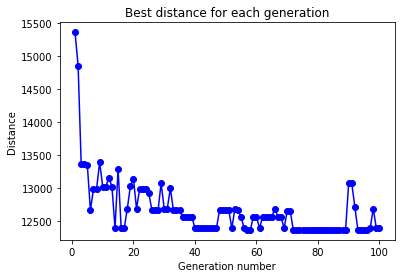

In [28]:
print(tsp_result)
print('-------------------------------')
first_col = [row[0] for row in tsp_result]
second_col = [row[1] for row in tsp_result]
print(first_col)
plt.plot(first_col,second_col,marker='o',color='b')
plt.title('Best distance for each generation')
plt.xlabel('Generation number')
plt.ylabel('Distance')

In [29]:
# PART 2: TSP by Brute Force
import itertools

In [30]:
def calculate_distance(route, distance_matrix):
    """Calculate the total distance of the given route 
       based on the distance matrix."""
    total_distance = 0
    for i in range(len(route) - 1):
        total_distance += distance_matrix[route[i]][route[i + 1]]
    total_distance += distance_matrix[route[-1]][route[0]] # Return to starting point
    return total_distance

def traveling_salesman(distance_matrix):
    """Find shortest route for the Traveling Salesman Problem."""
    num_cities = len(distance_matrix)
    cities = list(range(num_cities))
    
    # Generate all possible routes (permutations)
    all_routes = itertools.permutations(cities)
    min_distance = float('inf')
    best_route = None
    
    # Evaluate each route
    k = 0
    for route in all_routes:
        k = k + 1
        current_distance = calculate_distance(route, distance_matrix)
        if current_distance < min_distance:
            min_distance = current_distance
            best_route = route
    print('total number of routes by brute force = ', k)       
    return best_route, min_distance


In [31]:
# Running the TSP example by brute force

start_time = time.time()
best_route, min_distance = traveling_salesman(distance_matrix)

end_time = time.time()
# Calculate the time taken
time_taken = end_time - start_time 
print(f"Time taken: {time_taken:.2f} seconds")

print("Best Route:", best_route)
print("Minimum Distance:", min_distance)



total number of routes by brute force =  3628800
Time taken: 4.59 seconds
Best Route: (0, 4, 2, 1, 7, 6, 9, 3, 8, 5)
Minimum Distance: 12371


In [32]:
# Part 3:  TSP by Genetic Algorithm with Elitism
# This guarantees the very best individuals from 
# the current generation are passed to the next
# This prevents the loss of the fittest solutions.

count_calculate_fitness=0

class GeneticAlgorithm:
    
    # The `GeneticAlgorithm` class initializes the distance matrix, population size, mutation rate, 
    # and number of generations. It also creates an initial population of random routes.
    # population_size=100, mutation_rate=0.01, generations=500
    

    def __init__(self, distance_matrix, population_size=200, mutation_rate=0.01, generations=100):
        self.distance_matrix = distance_matrix
        self.population_size = population_size
        self.mutation_rate = mutation_rate
        self.generations = generations
        self.num_cities = len(distance_matrix)
        self.population = self.create_initial_population()
        
    def create_initial_population(self):
        print('inside initial ')
        """1. Create an initial population of random routes."""
        population = []
        for _ in range(self.population_size):
            route = list(range(self.num_cities))
            random.shuffle(route)  #randomize the list of cities and add to the population
            population.append(route)
        return population

    def calculate_fitness(self, route):
        """2. Calculate the fitness (inverse of distance) of a route."""
        total_distance = 0
        
        global count_calculate_fitness
        count_calculate_fitness = count_calculate_fitness + 1
        
        for i in range(len(route) - 1):
            total_distance += self.distance_matrix[route[i]][route[i + 1]]
        total_distance += self.distance_matrix[route[-1]][route[0]]  # Return to starting point
        #print('total_distance ',total_distance)
        return 1 / total_distance  # Fitness is the inverse of distance; the larger the better

    def select_parents(self):
        #print('inside select_parents')
        """Select two parents based on their fitness using tournament selection."""
        """where a subset of the population is chosen randomly, and the best among them is selected."""

        tournament_size = 5
        tournament = random.sample(self.population, tournament_size)
        tournament.sort(key=self.calculate_fitness, reverse=True)

        return tournament[0], tournament[1]  # The best two candidates are returned

    def crossover(self, parent1, parent2):
        #print('inside crossover')
        
        """Perform crossover between two parents to create a child."""
        """A crossover operation creates a child route by combining segments of two parent routes."""

        start, end = sorted(random.sample(range(self.num_cities), 2))
        child = [-1] * self.num_cities
        
        child[start:end] = parent1[start:end]
        
        current_position = end
        for city in parent2:
            if city not in child:
                child[current_position] = city
                current_position = (current_position + 1) % self.num_cities
                
        return child

    def mutate(self, route):
        """Mutate a route by swapping two cities in a route based on the mutation rate."""
        #print('inside mutate')
        for i in range(self.num_cities):
            if random.random() < self.mutation_rate:
                j = random.randint(0, self.num_cities - 1)
                route[i], route[j] = route[j], route[i]

    def evolve(self):
        """Evolve the population over generations."""
        counter = 0
        save_shortest_dist =[]
        
        # In each generation, there are 200 + 1 + (197 x 5) OR 1186 number of fitness count
        # Details:
        # best_route_tmp has 200
        # best_distance_tmp has 1
        # self.select_parents() has 5 per candidate in population; hence 197 x 5.
        # Total: if number_generation=100; population=200, it would be 1186 x 100
        # Final with another 201, or 118600 + 201 = 118801
        
        for kk in range(self.generations):  # for _ in range(self.generations):
            new_population = []
            counter = counter + 1
            # To get the best among the population in the current generation
                
            sort_population = self.population
            sort_population.sort(key=self.calculate_fitness, reverse=True)
            
            best1 = sort_population[0]
            best2 = sort_population[1]
            best3 = sort_population[2]
            
            best1_distance_tmp = 1 / self.calculate_fitness(best1)
            
            #best_route_tmp = max(self.population, key=self.calculate_fitness)           
            #best_distance_tmp = 1 / self.calculate_fitness(best_route_tmp)
            save_shortest_dist.append([counter, best1_distance_tmp ])     
            
            for _ in range(self.population_size - 3): # three less : add back the best 3 from current
                parent1, parent2 = self.select_parents()  #select two best parents/candidates
                child = self.crossover(parent1, parent2)  # crossover to get a child
                self.mutate(child)                        # mutate the child
                new_population.append(child)
            new_population.append(best1)  # add back the best 3 from current
            new_population.append(best2)
            new_population.append(best3)
            
            self.population = new_population  
                
        return save_shortest_dist

    def get_best_route(self):
        """Get the best route from the current population."""
        best_route = max(self.population, key=self.calculate_fitness)
        best_distance = 1 / self.calculate_fitness(best_route)
        print('total number of routes by GA = ',count_calculate_fitness)
        return best_route, best_distance, count_calculate_fitness


In [33]:
# Running the Genetic Algorithm for TSP
# Calcuate the time taken
ga = GeneticAlgorithm(distance_matrix)

start_time = time.time()
tsp_result = ga.evolve()

best_route, min_distance, fitness_count = ga.get_best_route()

end_time = time.time()
# Calculate the time taken
time_taken = end_time - start_time 
print(f"Time taken: {time_taken:.2f} seconds")

print("Best Route:", best_route)
print("Minimum Distance:", min_distance)
print("GA Fitness_count",fitness_count)

inside initial 
total number of routes by GA =  118801
Time taken: 0.48 seconds
Best Route: [1, 2, 4, 0, 5, 8, 3, 9, 6, 7]
Minimum Distance: 12371.0
GA Fitness_count 118801


Text(0, 0.5, 'Distance')

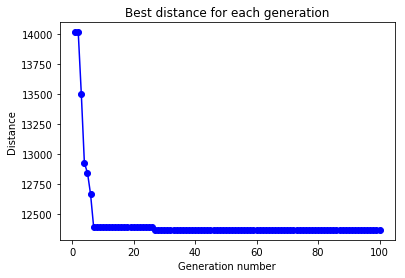

In [34]:
# Display the graph
first_col = [row[0] for row in tsp_result]
second_col = [row[1] for row in tsp_result]
plt.plot(first_col,second_col,marker='o',color='b')
plt.title('Best distance for each generation')
plt.xlabel('Generation number')
plt.ylabel('Distance')